# **Exploratory Data Analysis: Diabetes Health Indicators (BRFSS 2015)**

Notebook ini berisi eksplorasi awal terhadap dataset `diabetes_binary_health_indicators_BRFSS2015.csv` sebelum masuk ke tahap preprocessing dan pemodelan MLP. Fokusnya ada di empat hal: struktur dan kualitas data, ketidakseimbangan kelas, pola tiap fitur terhadap label, dan hubungan antarfitur. Setiap temuan di akhir notebook dipetakan ke keputusan preprocessing di `02_preprocessing.ipynb`.

**Penanggung jawab:** Afriyoga Haganta Tarigan (231110702)

## **1. Import Library dan Konfigurasi**

Root repository ditambahkan ke `sys.path` supaya modul `src/` bisa di-import dari folder `notebooks/`. Path dataset, daftar fitur, dan label kategori diambil dari `src/config.py` agar konsisten dengan notebook lain.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.append(str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid", context="notebook")

CLASS_COLORS = {0: "#4C72B0", 1: "#DD8452"}
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(fig, name):
    """Simpan grafik ke reports/figures supaya bisa langsung dipakai di laporan."""
    fig.savefig(config.FIGURES_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

# print("Root repository :", ROOT)
print("Dataset         :", config.RAW_DATA_PATH.relative_to(ROOT))

Dataset         : data\diabetes_binary_health_indicators_BRFSS2015.csv


## **2. Memuat Dataset**

Dataset dibaca langsung dari CSV mentah tanpa perubahan apa pun, supaya kondisi aslinya terlihat apa adanya.

In [2]:
df = pd.read_csv(config.RAW_DATA_PATH)
print(f"Jumlah baris : {df.shape[0]:,}")
print(f"Jumlah kolom : {df.shape[1]} (1 target + {df.shape[1] - 1} fitur)")
df.head()

Jumlah baris : 253,680
Jumlah kolom : 22 (1 target + 21 fitur)


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


**Interpretasi:** Dataset berisi 253.680 baris dan 22 kolom, terdiri dari 1 kolom target (`Diabetes_binary`) dan 21 fitur indikator kesehatan. Semua nilai tampil dalam format desimal (misalnya `1.0` dan `40.0`), padahal isinya berupa kode jawaban survei. Hal ini dicek lebih lanjut di bagian struktur data.

### **2.1 Kamus Fitur**

Kamus fitur disimpan di `config.FEATURE_INFO` dan menjadi acuan yang sama untuk laporan maupun form input aplikasi. Keterangan diambil dari deskripsi variabel dataset Kaggle yang diturunkan dari codebook BRFSS 2015 milik CDC. Kolom `nilai_di_data` dihitung langsung dari dataset supaya tidak ada perbedaan antara dokumentasi dan isi data.

In [3]:
def format_nilai(v):
    if isinstance(v, dict):
        return ", ".join(f"{k} = {lbl}" for k, lbl in v.items())
    return v

kamus = pd.DataFrame([
    {"fitur": col, "nama": info["nama"], "jenis": info["jenis"], "keterangan": info["keterangan"],
     "kode_nilai": format_nilai(info["nilai"]),
     "nilai_di_data": f"{int(df[col].min())}-{int(df[col].max())}"}
    for col, info in config.FEATURE_INFO.items()
])
with pd.option_context("display.max_colwidth", 90):
    display(kamus)

,fitur,nama,jenis,keterangan,kode_nilai,nilai_di_data
0,HighBP,Tekanan darah tinggi,biner,Pernah dinyatakan memiliki tekanan darah tinggi,"0 = Tidak, 1 = Ya",0-1
1,HighChol,Kolesterol tinggi,biner,Pernah dinyatakan memiliki kolesterol tinggi,"0 = Tidak, 1 = Ya",0-1
2,CholCheck,Cek kolesterol,biner,Melakukan cek kolesterol dalam 5 tahun terakhir,"0 = Tidak, 1 = Ya",0-1
3,BMI,Indeks massa tubuh,numerik,"Body Mass Index (berat kg / tinggi m kuadrat), bilangan bulat","12-98 di data mentah, 12-69 setelah cleaning",12-98
4,Smoker,Pernah merokok,biner,Pernah merokok minimal 100 batang (5 bungkus) seumur hidup,"0 = Tidak, 1 = Ya",0-1
5,Stroke,Riwayat stroke,biner,Pernah dinyatakan mengalami stroke,"0 = Tidak, 1 = Ya",0-1
6,HeartDiseaseorAttack,Penyakit jantung,biner,Riwayat penyakit jantung koroner (CHD) atau serangan jantung (MI),"0 = Tidak, 1 = Ya",0-1
7,PhysActivity,Aktivitas fisik,biner,Melakukan aktivitas fisik di luar pekerjaan dalam 30 hari terakhir,"0 = Tidak, 1 = Ya",0-1
8,Fruits,Konsumsi buah,biner,Makan buah 1 kali atau lebih per hari,"0 = Tidak, 1 = Ya",0-1
9,Veggies,Konsumsi sayur,biner,Makan sayur 1 kali atau lebih per hari,"0 = Tidak, 1 = Ya",0-1


**Interpretasi:** Kamus fitur menunjukkan bahwa hampir semua fitur berasal dari pertanyaan survei yang dijawab sendiri oleh responden, misalnya "pernah dinyatakan memiliki tekanan darah tinggi". Artinya data ini mencatat apa yang diketahui dan dilaporkan responden, bukan hasil pemeriksaan laboratorium.

Ada dua hal yang perlu dicatat untuk laporan dan aplikasi. Pertama, `MentHlth` dan `PhysHlth` berisi 0 sampai 30 hari, bukan 1 sampai 30, dan nilai 0 (tidak pernah) justru jawaban yang paling banyak. Form aplikasi wajib mengizinkan input 0. Kedua, `Smoker` bukan status merokok saat ini, melainkan apakah responden pernah merokok minimal 100 batang seumur hidup. Pertanyaan di aplikasi harus ditulis sesuai definisi ini supaya input pengguna sama maknanya dengan data training.

## **3. Struktur dan Tipe Data**

Pemeriksaan tipe data dan jumlah nilai unik per kolom. Dari jumlah nilai unik bisa diketahui mana fitur biner, ordinal, dan numerik, karena semua kolom tersimpan sebagai angka.

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_binary       253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Fruits                253680 non-null  float64
 10  Veggies               253680 non-null  float64
 11  HvyAlcoholConsump     253680 non-null  float64
 12  AnyHealthcare         253680 non-null  float64
 13  NoDocbcCost           253680 non-null  float64
 14  GenHlth               253680 non-null  float64
 15  MentHlth   

In [5]:
def feature_type(col):
    if col == config.TARGET_COL:
        return "target"
    if col in config.BINARY_COLS:
        return "biner"
    if col in config.ORDINAL_COLS:
        return "ordinal"
    return "numerik"

struktur = pd.DataFrame({
    "tipe_data": df.dtypes.astype(str),
    "jenis_fitur": [feature_type(c) for c in df.columns],
    "nilai_unik": df.nunique(),
    "min": df.min(),
    "max": df.max(),
    "semua_bilangan_bulat": [(df[c] % 1 == 0).all() for c in df.columns],
})
display(struktur)
print(struktur["jenis_fitur"].value_counts().to_string())

,tipe_data,jenis_fitur,nilai_unik,min,max,semua_bilangan_bulat
Diabetes_binary,float64,target,2,0.0,1.0,True
HighBP,float64,biner,2,0.0,1.0,True
HighChol,float64,biner,2,0.0,1.0,True
CholCheck,float64,biner,2,0.0,1.0,True
BMI,float64,numerik,84,12.0,98.0,True
Smoker,float64,biner,2,0.0,1.0,True
Stroke,float64,biner,2,0.0,1.0,True
HeartDiseaseorAttack,float64,biner,2,0.0,1.0,True
PhysActivity,float64,biner,2,0.0,1.0,True
Fruits,float64,biner,2,0.0,1.0,True


jenis_fitur
biner      14
ordinal     4
numerik     3
target      1


**Interpretasi:** Seluruh kolom bertipe `float64`, tetapi kolom `semua_bilangan_bulat` menunjukkan tidak ada satu pun nilai pecahan. Artinya angka desimal hanya efek format penyimpanan, bukan informasi yang bermakna. Karena itu, fungsi `load_raw_data()` di `src/preprocessing.py` langsung mengubah semua kolom ke integer.

Komposisi fiturnya adalah 14 fitur biner, 4 fitur ordinal, dan 3 fitur numerik. Fitur ordinal (`GenHlth`, `Age`, `Education`, `Income`) punya urutan yang jelas, misalnya kategori umur 1 lebih muda dari kategori 13. Jadi fitur ini tidak perlu di-*one-hot encode* dan cukup diperlakukan sebagai angka lalu di-scaling bersama fitur numerik.

## **4. Statistik Deskriptif**

Ringkasan statistik untuk melihat rentang nilai, rata-rata, dan sebaran. Untuk kolom biner, nilai `mean` sama dengan proporsi responden yang menjawab "ya".

In [6]:
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
Diabetes_binary,253680.0,0.139,0.346,0.0,0.0,0.0,0.0,1.0
HighBP,253680.0,0.429,0.495,0.0,0.0,0.0,1.0,1.0
HighChol,253680.0,0.424,0.494,0.0,0.0,0.0,1.0,1.0
CholCheck,253680.0,0.963,0.190,0.0,1.0,1.0,1.0,1.0
BMI,253680.0,28.382,6.609,12.0,24.0,27.0,31.0,98.0
Smoker,253680.0,0.443,0.497,0.0,0.0,0.0,1.0,1.0
Stroke,253680.0,0.041,0.197,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,253680.0,0.094,0.292,0.0,0.0,0.0,0.0,1.0
PhysActivity,253680.0,0.757,0.429,0.0,1.0,1.0,1.0,1.0
Fruits,253680.0,0.634,0.482,0.0,0.0,1.0,1.0,1.0


**Interpretasi:** Ada dua hal yang langsung terlihat. Pertama, skala antarfitur berbeda jauh. Fitur biner hanya 0 sampai 1, sementara `BMI` berada di rentang 12 sampai 98 dan `MentHlth`/`PhysHlth` di rentang 0 sampai 30. MLP yang dilatih dengan gradient descent akan lebih stabil kalau skala ini disamakan, jadi scaling wajib dilakukan.

Kedua, beberapa fitur biner sangat timpang. `CholCheck` bernilai 1 pada 96,3% responden dan `AnyHealthcare` pada 95,1%, sebaliknya `Stroke` hanya 4,1% dan `HvyAlcoholConsump` 5,6%. Fitur seperti ini tetap dipertahankan, tetapi kontribusinya bagi model kemungkinan kecil karena variasinya sedikit. `MentHlth` juga terlihat sangat miring karena median dan kuartil pertamanya 0, sedangkan standar deviasinya (7,4) lebih besar dari rata-ratanya (3,2).

## **5. Missing Value dan Data Duplikat**

Selain missing value, data duplikat perlu dicek dengan serius. Pada data survei yang hampir semua fiturnya biner, dua responden berbeda bisa saja punya jawaban identik. Masalahnya, kalau baris yang sama persis muncul di data train sekaligus test, skor evaluasi akan terlihat lebih bagus dari kemampuan model yang sebenarnya.

In [7]:
missing = df.isna().sum()
print("Total missing value :", int(missing.sum()))

dup_mask = df.duplicated()
print(f"Baris duplikat (identik di semua kolom) : {dup_mask.sum():,} ({dup_mask.mean():.2%})")

print("\nLabel pada baris duplikat (salinan ke-2 dan seterusnya):")
print(df.loc[dup_mask, config.TARGET_COL].value_counts().rename(index=config.CLASS_LABELS).to_string())

Total missing value : 0
Baris duplikat (identik di semua kolom) : 24,206 (9.54%)

Label pada baris duplikat (salinan ke-2 dan seterusnya):
Diabetes_binary
Tidak diabetes    23957
Diabetes            249


In [8]:
# Profil yang paling sering muncul berulang
fitur = config.FEATURE_COLS
profil_berulang = (
    df[df.duplicated(keep=False)]
    .groupby(fitur + [config.TARGET_COL]).size()
    .sort_values(ascending=False)
    .rename("jumlah_kemunculan")
    .reset_index()
)
profil_berulang.head(5)

,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary,jumlah_kemunculan
0,0.0,0.0,1.0,21.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,6.0,6.0,8.0,0.0,59
1,0.0,0.0,1.0,23.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,6.0,6.0,8.0,0.0,55
2,0.0,0.0,1.0,23.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,7.0,6.0,8.0,0.0,53
3,0.0,0.0,1.0,21.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,5.0,6.0,8.0,0.0,52
4,0.0,0.0,1.0,22.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,6.0,6.0,8.0,0.0,52


In [9]:
# Vektor fitur identik tetapi labelnya berbeda (noise label yang tidak bisa dipisahkan model mana pun)
label_per_profil = df.groupby(fitur)[config.TARGET_COL].nunique()
konflik = label_per_profil[label_per_profil > 1]
baris_konflik = df.set_index(fitur).index.isin(konflik.index).sum()
print(f"Profil fitur dengan dua label berbeda : {len(konflik):,}")
print(f"Jumlah baris yang terlibat            : {baris_konflik:,} ({baris_konflik / len(df):.2%} dari data)")

Profil fitur dengan dua label berbeda : 1,566
Jumlah baris yang terlibat            : 5,218 (2.06% dari data)


**Interpretasi:** Tidak ada missing value sama sekali, jadi tahap imputasi tidak diperlukan.

Yang perlu diperhatikan adalah 24.206 baris duplikat (9,54% data). Hampir semuanya (23.957 baris) berlabel tidak diabetes. Dari tabel profil yang paling sering berulang, polanya juga masuk akal: responden usia 40 sampai 54 tahun, BMI normal, tanpa riwayat penyakit, pendidikan dan pendapatan di kategori tertinggi. Dugaan kami, duplikat ini bukan kesalahan input, tetapi memang banyak responden sehat yang jawabannya persis sama karena fiturnya kasar (sebagian besar hanya 0/1).

Walaupun begitu, duplikat tetap akan dihapus. Alasannya teknis: kalau satu profil muncul 59 kali, hampir pasti salinannya tersebar di data train dan test sekaligus, sehingga model dinilai dari data yang sebenarnya sudah dilihat saat training.

Temuan lain yang penting adalah 1.566 profil fitur yang muncul dengan dua label berbeda, melibatkan 5.218 baris (2,06%). Untuk baris-baris ini, model apa pun tidak mungkin benar semua karena input yang sama persis punya jawaban berbeda. Ini jadi salah satu bukti bahwa masalah ini kompleks, dan baris tersebut tetap dipertahankan karena memang mencerminkan kondisi data nyata.

## **6. Distribusi Kelas Target**

Label `Diabetes_binary` bernilai 1 untuk responden diabetes dan 0 untuk responden yang tidak diabetes. Makna label ini diverifikasi di Bagian 6.1 karena berbeda dengan deskripsi di halaman Kaggle. Distribusi dihitung pada data mentah dan setelah duplikat dihapus.

In [10]:
def distribusi(series):
    vc = series.value_counts().sort_index()
    return pd.DataFrame({
        "kelas": vc.index.map(config.CLASS_LABELS),
        "jumlah": vc.values,
        "persentase": (vc.values / vc.sum() * 100).round(2),
    })

df_dedup = df.drop_duplicates()
dist_raw = distribusi(df[config.TARGET_COL])
dist_dedup = distribusi(df_dedup[config.TARGET_COL])

print("Data mentah")
display(dist_raw)
print("Setelah duplikat dihapus")
display(dist_dedup)

rasio = dist_raw["jumlah"].iloc[0] / dist_raw["jumlah"].iloc[1]
print(f"Rasio kelas negatif : positif (mentah) = {rasio:.2f} : 1")
print(f"Akurasi jika model selalu menebak 'Tidak diabetes' = {dist_raw['persentase'].iloc[0]:.2f}%")

Data mentah


,kelas,jumlah,persentase
0,Tidak diabetes,218334,86.07
1,Diabetes,35346,13.93


Setelah duplikat dihapus


,kelas,jumlah,persentase
0,Tidak diabetes,194377,84.71
1,Diabetes,35097,15.29


Rasio kelas negatif : positif (mentah) = 6.18 : 1
Akurasi jika model selalu menebak 'Tidak diabetes' = 86.07%


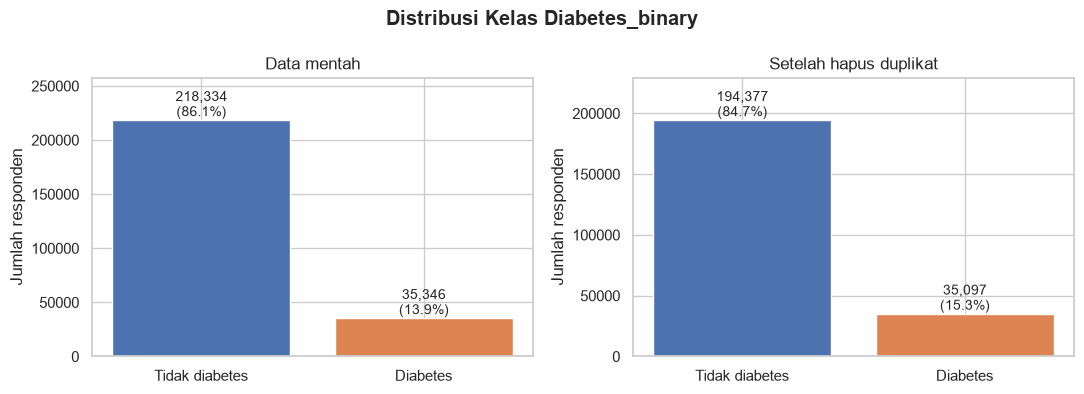

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (judul, dist) in zip(axes, [("Data mentah", dist_raw), ("Setelah hapus duplikat", dist_dedup)]):
    bars = ax.bar(dist["kelas"], dist["jumlah"], color=[CLASS_COLORS[0], CLASS_COLORS[1]])
    for bar, pct in zip(bars, dist["persentase"]):
        ax.annotate(f"{bar.get_height():,.0f}\n({pct:.1f}%)", (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                    ha="center", va="bottom", fontsize=10)
    ax.set_title(judul)
    ax.set_ylabel("Jumlah responden")
    ax.set_ylim(0, dist["jumlah"].max() * 1.18)
fig.suptitle("Distribusi Kelas Diabetes_binary", fontweight="bold")
fig.tight_layout()
save_fig(fig, "eda_01_distribusi_kelas")
plt.show()

**Interpretasi:** Kelas sangat tidak seimbang. Sebanyak 86,07% responden berlabel tidak diabetes dan hanya 13,93% berlabel diabetes, dengan rasio sekitar 6,18 : 1. Setelah duplikat dihapus, proporsi kelas positif sedikit naik menjadi 15,29% karena duplikat didominasi kelas negatif.

Angka yang paling penting dari bagian ini: model yang selalu menebak "tidak diabetes" sudah mendapat akurasi 86,07% tanpa belajar apa pun. Karena itu accuracy tidak bisa jadi metrik utama. Evaluasi akan difokuskan ke recall, precision, F1-score, dan PR-AUC kelas positif. Kondisi ini juga yang menjadi dasar fitur unik pertama (penanganan data tidak seimbang), serta alasan pembagian data harus dilakukan secara *stratified*.

### **6.1 Verifikasi Makna Label dengan File Diabetes_012**

Halaman Kaggle menyebut label 1 berisi responden prediabetes atau diabetes. Dataset yang sama juga menyediakan file `diabetes_012_health_indicators_BRFSS2015.csv` dengan label tiga kelas (0 = tidak diabetes atau diabetes hanya saat hamil, 1 = prediabetes, 2 = diabetes). Kedua file dibandingkan baris per baris untuk memastikan makna label 1 yang sebenarnya. File Diabetes_012 hanya dipakai untuk verifikasi ini dan untuk analisis kesalahan, **tidak** dipakai untuk training.

In [12]:
df012 = pd.read_csv(config.REFERENCE_012_PATH)
print("Jumlah baris sama        :", len(df012) == len(df))
print("21 fitur identik per baris:", df012[config.FEATURE_COLS].equals(df[config.FEATURE_COLS]))

label_012 = df012["Diabetes_012"].map({0: "0 = tidak diabetes", 1: "1 = prediabetes", 2: "2 = diabetes"})
pd.crosstab(label_012, df[config.TARGET_COL].astype(int).rename("Diabetes_binary"), margins=True, margins_name="Total")

Jumlah baris sama        : True
21 fitur identik per baris: True


Diabetes_binary,0,1,Total
Diabetes_012,,,
0 = tidak diabetes,213703,0,213703
1 = prediabetes,4631,0,4631
2 = diabetes,0,35346,35346
Total,218334,35346,253680


**Interpretasi:** Kedua file berisi 253.680 baris dengan 21 fitur yang identik baris per baris, jadi keduanya bisa dibandingkan langsung. Hasil crosstab menunjukkan:

- Seluruh 35.346 responden berlabel 2 (diabetes) di file Diabetes_012 menjadi label 1 di file kita.
- Sebanyak **4.631 responden prediabetes masuk ke label 0**, bukan label 1.

Jadi deskripsi di halaman Kaggle tidak sesuai dengan isi datanya. Label 1 di file yang dipakai proyek ini **hanya berisi responden diabetes**. Label 0 berisi responden tanpa diabetes, responden prediabetes, dan responden yang hanya mengalami diabetes saat hamil.

Temuan ini berdampak ke beberapa hal. Topik proyek tetap sesuai, yaitu prediksi risiko diabetes, tetapi seluruh laporan dan aplikasi harus menyebut kelas positif sebagai **diabetes**, bukan prediabetes atau diabetes. Selain itu, responden prediabetes yang tercampur di label 0 (1,83% dari data) adalah orang yang kondisinya sudah mengarah ke diabetes. Model kemungkinan memberi probabilitas tinggi pada sebagian dari mereka sehingga tercatat sebagai *false positive*. Dugaan ini bisa dicek di tahap analisis kesalahan dengan memakai file Diabetes_012 sebagai pembanding.

## **7. Distribusi Fitur Numerik dan Ordinal**

Histogram dibuat terpisah per kelas dengan skala densitas (`stat="density"`), karena jumlah kelas positif jauh lebih kecil. Kalau memakai jumlah mentah, bentuk distribusi kelas positif akan tertutup oleh kelas negatif.

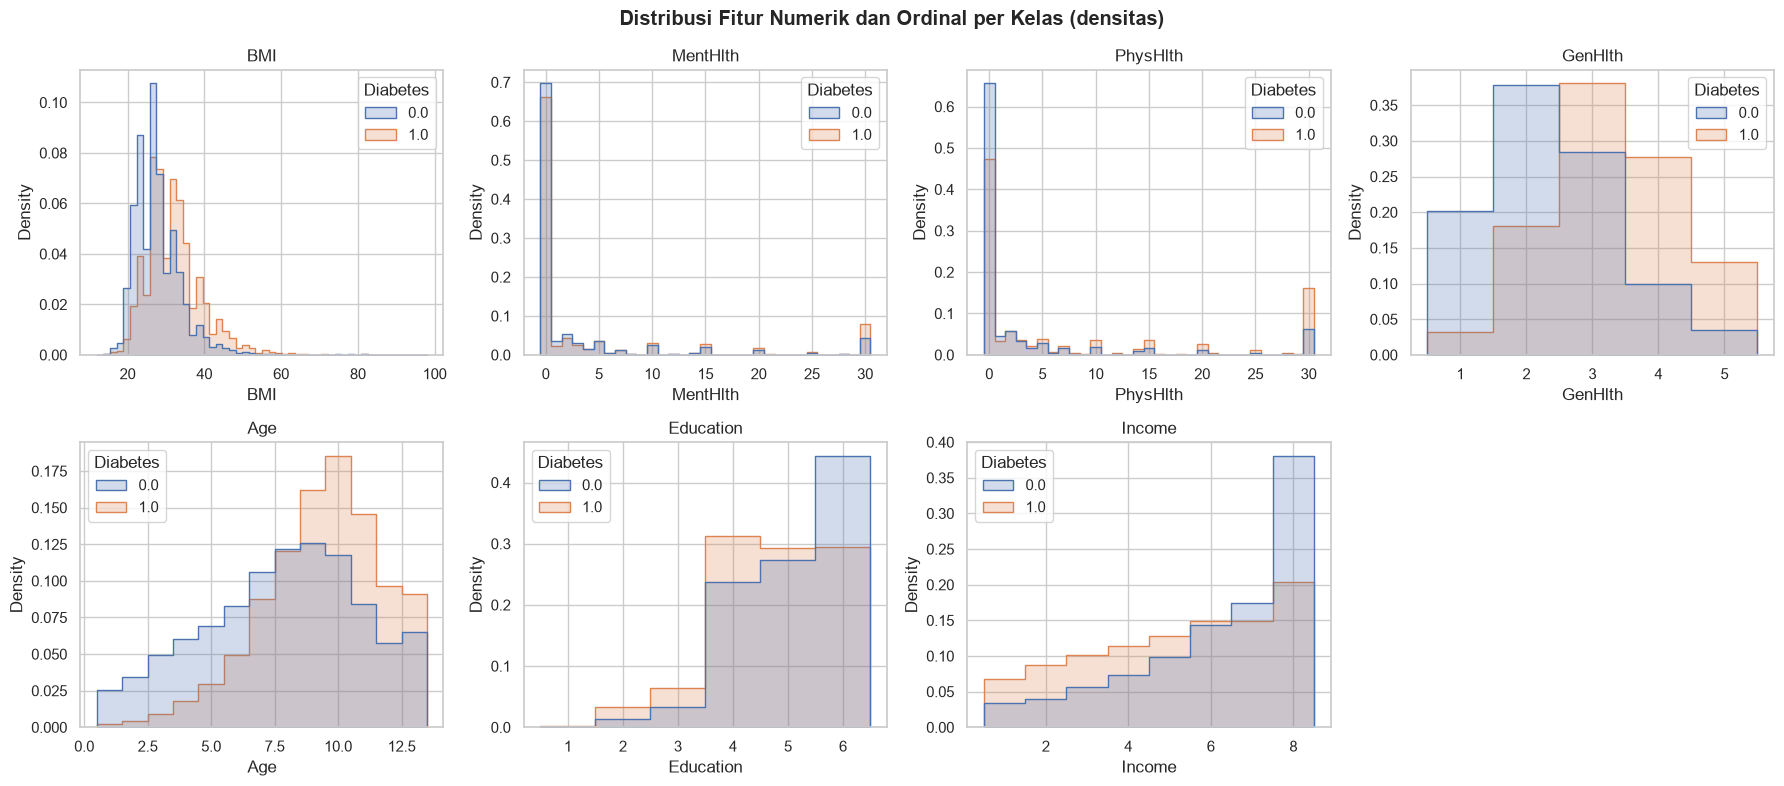

In [13]:
num_cols = config.CONTINUOUS_COLS + config.ORDINAL_COLS
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, num_cols):
    discrete = df[col].nunique() <= 31
    sns.histplot(data=df, x=col, hue=config.TARGET_COL, stat="density", common_norm=False,
                 discrete=discrete, element="step", palette=CLASS_COLORS, ax=ax,
                 bins=None if discrete else 50)
    ax.set_title(col)
    ax.get_legend().set_title("Diabetes")
axes.flat[-1].axis("off")
fig.suptitle("Distribusi Fitur Numerik dan Ordinal per Kelas (densitas)", fontweight="bold")
fig.tight_layout()
save_fig(fig, "eda_02_histogram_numerik")
plt.show()

In [14]:
# Proporsi nilai 0 pada MentHlth dan PhysHlth (jumlah hari tidak sehat dalam 30 hari terakhir)
for col in ["MentHlth", "PhysHlth"]:
    print(f"{col}: {(df[col] == 0).mean():.2%} responden menjawab 0 hari, "
          f"{(df[col] == 30).mean():.2%} menjawab 30 hari")

# Rata-rata tiap fitur numerik/ordinal per kelas
df.groupby(config.TARGET_COL)[num_cols].mean().rename(index=config.CLASS_LABELS).T.round(2)

MentHlth: 69.25% responden menjawab 0 hari, 4.77% menjawab 30 hari
PhysHlth: 63.09% responden menjawab 0 hari, 7.65% menjawab 30 hari


Diabetes_binary,Tidak diabetes,Diabetes
BMI,27.81,31.94
MentHlth,2.98,4.46
PhysHlth,3.64,7.95
GenHlth,2.39,3.29
Age,7.81,9.38
Education,5.10,4.75
Income,6.19,5.21


**Interpretasi:** Hampir semua fitur menunjukkan pergeseran distribusi antara kedua kelas, meskipun daerahnya masih banyak tumpang tindih.

- **BMI:** distribusi kelas positif bergeser ke kanan. Rata-ratanya 31,94 dibanding 27,81 pada kelas negatif.
- **GenHlth:** kelas negatif menumpuk di nilai 1 sampai 2 (kesehatan istimewa dan sangat baik), sedangkan kelas positif menumpuk di 3 sampai 5.
- **Age:** kelas positif terkonsentrasi di kategori 9 sampai 11 (60 sampai 74 tahun).
- **MentHlth dan PhysHlth:** sebanyak 69,25% dan 63,09% responden menjawab 0 hari, lalu ada lonjakan kecil di angka 10, 15, 20, dan 30. Ini pola khas survei karena orang cenderung membulatkan jawaban. Rata-rata `PhysHlth` kelas positif (7,95 hari) lebih dari dua kali kelas negatif (3,64 hari).
- **Education dan Income:** kelas negatif jauh lebih banyak berada di kategori tertinggi.

Karena distribusi `MentHlth` dan `PhysHlth` tidak normal dan didominasi nilai 0, StandardScaler tidak akan membuatnya berbentuk normal. Untuk MLP hal ini masih bisa diterima, tetapi pilihan transformasi tambahan akan dibandingkan di notebook preprocessing.

## **8. Fitur Ordinal terhadap Tingkat Diabetes**

Untuk fitur ordinal, yang lebih informatif adalah persentase responden berlabel 1 di setiap kategori. Garis putus-putus menunjukkan prevalensi rata-rata seluruh data sebagai pembanding.

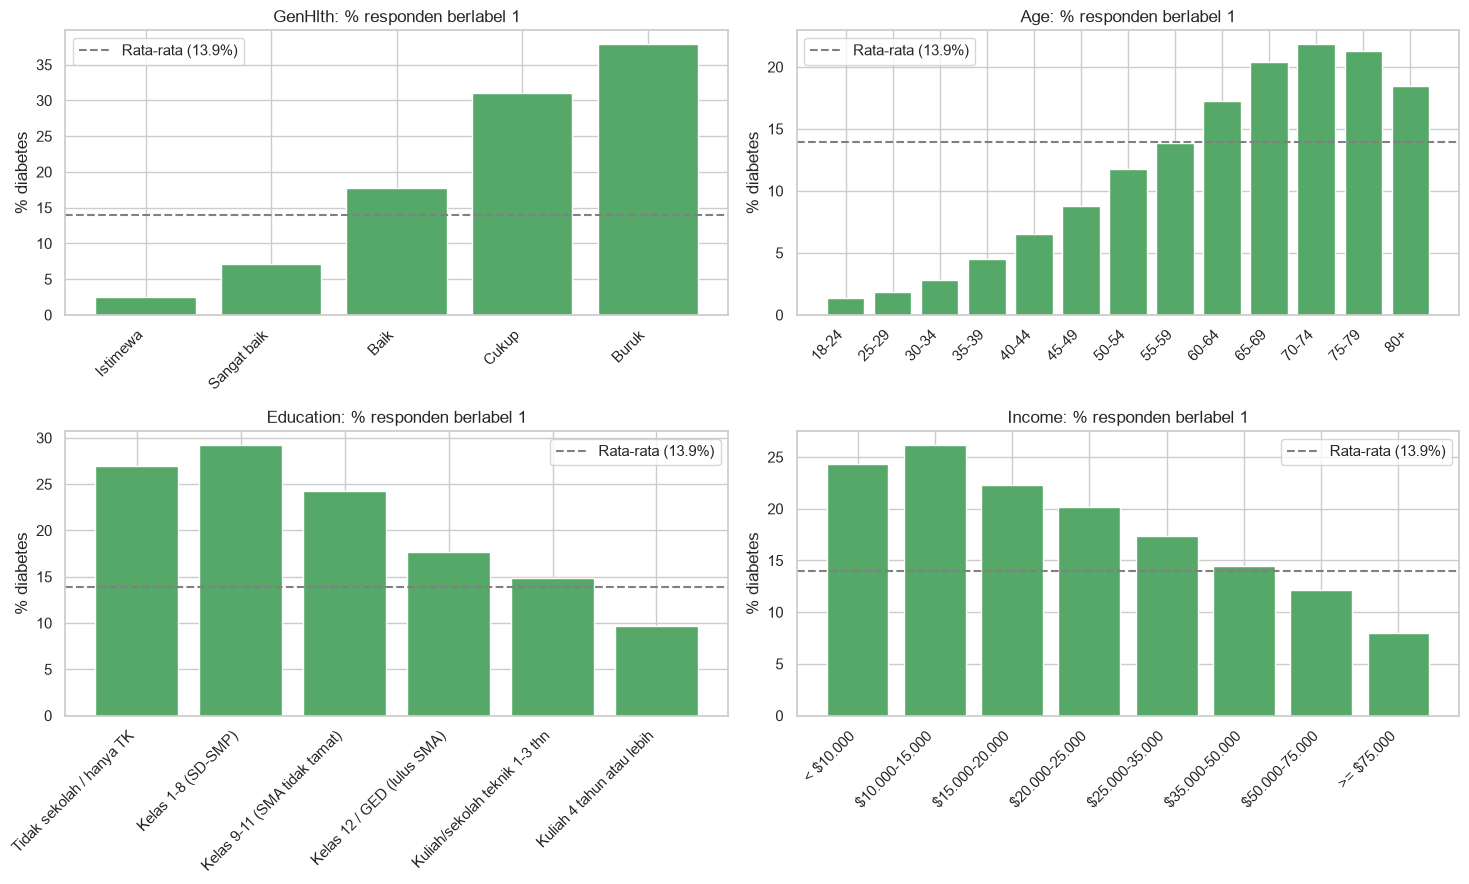

In [15]:
prevalensi = df[config.TARGET_COL].mean()
label_map = {"Age": config.AGE_LABELS, "GenHlth": config.GENHLTH_LABELS,
             "Education": config.EDUCATION_LABELS, "Income": config.INCOME_LABELS}

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, col in zip(axes.flat, config.ORDINAL_COLS):
    rate = df.groupby(col)[config.TARGET_COL].mean() * 100
    ax.bar([label_map[col][int(k)] for k in rate.index], rate.values, color="#55A868")
    ax.axhline(prevalensi * 100, ls="--", color="gray", label=f"Rata-rata ({prevalensi:.1%})")
    ax.set_title(f"{col}: % responden berlabel 1")
    ax.set_ylabel("% diabetes")
    ax.tick_params(axis="x", rotation=45)
    for lbl in ax.get_xticklabels():
        lbl.set_ha("right")
    ax.legend()
fig.tight_layout()
save_fig(fig, "eda_03_ordinal_vs_target")
plt.show()

**Interpretasi:** Keempat fitur ordinal punya hubungan yang hampir monoton dengan label, dan ini yang membuat keputusan memperlakukannya sebagai angka (bukan one-hot) cukup beralasan.

- **GenHlth** paling tajam. Responden dengan kesehatan "Istimewa" hanya 2,52% yang berlabel 1, sedangkan pada kategori "Buruk" mencapai 37,89%.
- **Age** naik terus dari 1,37% (18 sampai 24 tahun) hingga puncaknya 21,85% di kelompok 70 sampai 74 tahun, lalu sedikit turun menjadi 18,48% di kelompok 80+.
- **Education** dan **Income** bergerak berlawanan. Kelompok pendapatan tertinggi hanya 7,96%, sedangkan kelompok pendapatan $10.000 sampai $15.000 mencapai 26,19%. Untuk Education, kategori 1 hanya berisi 174 responden sehingga persentasenya kurang stabil dibanding kategori lain.

Pola Income dan Education ini menarik karena keduanya bukan faktor biologis. Hubungannya kemungkinan besar lewat faktor lain seperti pola makan, akses layanan kesehatan, dan usia, jadi ini korelasi, bukan sebab akibat langsung.

## **9. Fitur Biner terhadap Tingkat Diabetes**

Grafik ini membandingkan persentase label 1 pada responden yang menjawab "tidak" (0) dan "ya" (1) untuk setiap fitur biner. Semakin jauh jarak kedua batang, semakin kuat sinyal fitur tersebut.

,fitur,rate_0,rate_1,proporsi_nilai_1,selisih
0,HeartDiseaseorAttack,11.95,32.97,9.42,21.02
1,DiffWalk,10.53,30.75,16.82,20.21
2,Stroke,13.18,31.75,4.06,18.57
3,HighBP,6.04,24.45,42.90,18.41
4,HighChol,7.98,22.01,42.41,14.03
5,CholCheck,2.54,14.37,96.27,11.83
6,Smoker,12.06,16.29,44.32,4.24
7,NoDocbcCost,13.60,17.52,8.42,3.92
8,AnyHealthcare,11.45,14.06,95.11,2.61
9,Sex,12.97,15.16,44.03,2.19


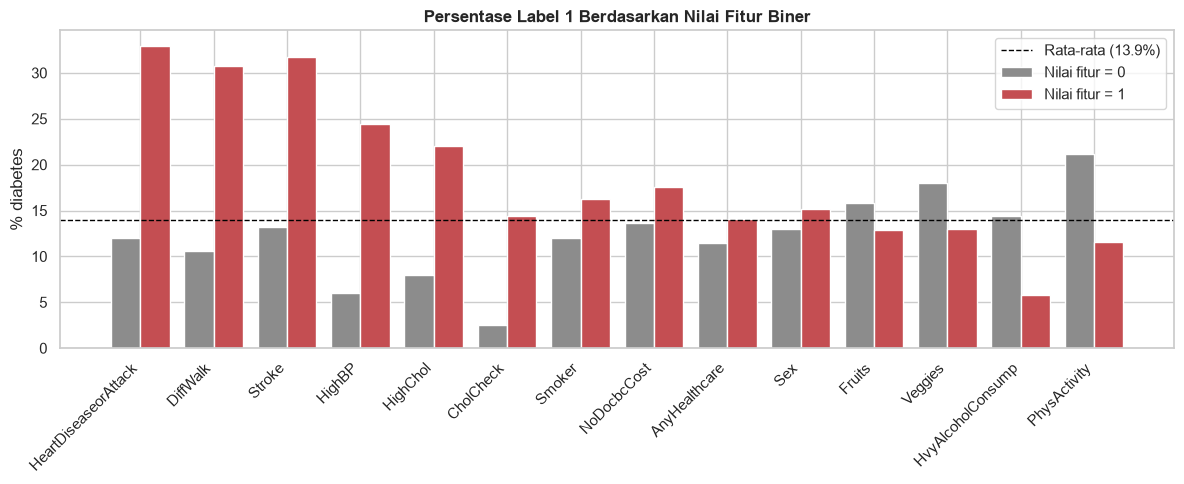

In [16]:
rows = []
for col in config.BINARY_COLS:
    rate = df.groupby(col)[config.TARGET_COL].mean() * 100
    rows.append({"fitur": col, "rate_0": rate.get(0, np.nan), "rate_1": rate.get(1, np.nan),
                 "proporsi_nilai_1": df[col].mean() * 100})
biner = pd.DataFrame(rows)
biner["selisih"] = biner["rate_1"] - biner["rate_0"]
biner = biner.sort_values("selisih", ascending=False).reset_index(drop=True)
display(biner.round(2))

fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(biner))
ax.bar(x - 0.2, biner["rate_0"], width=0.4, label="Nilai fitur = 0", color="#8C8C8C")
ax.bar(x + 0.2, biner["rate_1"], width=0.4, label="Nilai fitur = 1", color="#C44E52")
ax.axhline(prevalensi * 100, ls="--", color="black", lw=1, label=f"Rata-rata ({prevalensi:.1%})")
ax.set_xticks(x)
ax.set_xticklabels(biner["fitur"], rotation=45, ha="right")
ax.set_ylabel("% diabetes")
ax.set_title("Persentase Label 1 Berdasarkan Nilai Fitur Biner", fontweight="bold")
ax.legend()
fig.tight_layout()
save_fig(fig, "eda_04_biner_vs_target")
plt.show()

**Interpretasi:** Fitur biner dengan sinyal paling kuat adalah `HeartDiseaseorAttack` (32,97% berlabel 1 jika bernilai 1, dibanding 11,95% jika 0), `DiffWalk`, `Stroke`, dan `HighBP`. Hasil ini sejalan dengan pengetahuan umum bahwa diabetes sering muncul bersama penyakit kardiovaskular dan hipertensi.

Ada dua pola yang perlu dibaca hati-hati:

1. **CholCheck** terlihat kuat (14,37% vs 2,54%), padahal fitur ini hanya mencatat apakah responden pernah cek kolesterol dalam 5 tahun terakhir. Penjelasan yang paling masuk akal adalah label di dataset ini berasal dari pengakuan responden bahwa ia pernah didiagnosis dokter. Orang yang jarang memeriksakan diri juga lebih kecil kemungkinannya terdiagnosis, sehingga sebagian dari kelompok ini bisa jadi penderita yang belum terdeteksi.
2. **HvyAlcoholConsump** justru berasosiasi negatif (5,84% vs 14,42%). Ini tidak berarti alkohol melindungi dari diabetes. Kemungkinannya, penderita yang sudah terdiagnosis disarankan mengurangi alkohol, jadi arah hubungannya terbalik.

Sementara itu `Sex`, `AnyHealthcare`, `Fruits`, dan `NoDocbcCost` hanya memberi selisih di bawah 4 poin persen.

## **10. Pemeriksaan Outlier BMI**

BMI adalah satu-satunya fitur kontinu dengan rentang lebar. Nilai BMI di atas 60 sangat jarang secara klinis, jadi perlu dicek apakah nilai ekstrem tersebut masih mengikuti pola risiko yang wajar atau justru terlihat seperti kesalahan input.

In [17]:
print(df["BMI"].quantile([0.01, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999]).to_string())
for batas in [50, 60, 70, 80]:
    n = (df["BMI"] > batas).sum()
    print(f"BMI > {batas}: {n:,} baris ({n / len(df):.3%})")

0.010    18.0
0.250    24.0
0.500    27.0
0.750    31.0
0.950    40.0
0.990    50.0
0.999    81.0
BMI > 50: 2,175 baris (0.857%)
BMI > 60: 805 baris (0.317%)
BMI > 70: 584 baris (0.230%)
BMI > 80: 279 baris (0.110%)


,jumlah,persen_label_1
BMI,,
<18.5,3127,5.40
18.5-25,68953,5.70
25-30,93749,11.40
30-35,53451,19.23
35-40,20663,27.44
40-50,11190,33.57
50-60,1679,39.01
60-70,269,42.75
70-80,318,12.26


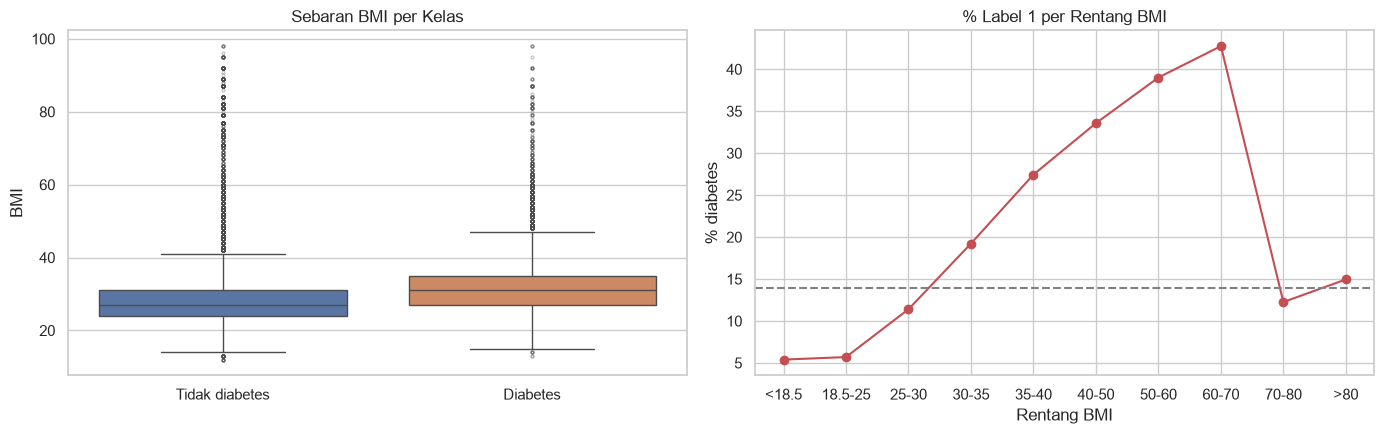

In [18]:
bins = [0, 18.5, 25, 30, 35, 40, 50, 60, 70, 80, 100]
labels = ["<18.5", "18.5-25", "25-30", "30-35", "35-40", "40-50", "50-60", "60-70", "70-80", ">80"]
bmi_grp = pd.cut(df["BMI"], bins=bins, labels=labels, right=False)
bmi_tabel = df.groupby(bmi_grp, observed=True)[config.TARGET_COL].agg(jumlah="size", persen_label_1="mean")
bmi_tabel["persen_label_1"] = (bmi_tabel["persen_label_1"] * 100).round(2)
display(bmi_tabel)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=df, x=config.TARGET_COL, y="BMI", hue=config.TARGET_COL, palette=CLASS_COLORS,
            legend=False, ax=axes[0], flierprops={"markersize": 2, "alpha": 0.3})
axes[0].set_xticks([0, 1], [config.CLASS_LABELS[0], config.CLASS_LABELS[1]])
axes[0].set_xlabel("")
axes[0].set_title("Sebaran BMI per Kelas")
axes[1].plot(bmi_tabel.index.astype(str), bmi_tabel["persen_label_1"], marker="o", color="#C44E52")
axes[1].axhline(prevalensi * 100, ls="--", color="gray")
axes[1].set_title("% Label 1 per Rentang BMI")
axes[1].set_xlabel("Rentang BMI")
axes[1].set_ylabel("% diabetes")
fig.tight_layout()
save_fig(fig, "eda_05_outlier_bmi")
plt.show()

**Interpretasi:** Sebanyak 99% responden memiliki BMI 50 ke bawah, dan hanya 0,24% (599 baris) yang memiliki BMI 70 ke atas.

Grafik sebelah kanan memperlihatkan pola yang paling menarik di notebook ini. Persentase label 1 naik konsisten dari 5,40% (BMI di bawah 18,5) sampai 42,75% (BMI 60 sampai 70), lalu tiba-tiba turun ke 12,26% pada BMI 70 sampai 80 dan 14,95% pada BMI di atas 80. Secara klinis, risiko diabetes tidak masuk akal turun drastis pada obesitas paling ekstrem. Karena BMI dihitung dari tinggi dan berat badan yang dilaporkan sendiri oleh responden, nilai 70 ke atas lebih mungkin berasal dari kesalahan pengisian.

Ada tiga pilihan penanganan yang akan dibandingkan di notebook preprocessing: (a) menghapus baris dengan BMI 70 ke atas, (b) clipping, dan (c) membiarkannya. Clipping kurang cocok di sini karena baris yang dicurigai salah malah akan dipindahkan ke zona risiko tertinggi, padahal labelnya tidak mengikuti pola tersebut. Rekomendasi sementara kami adalah opsi (a), dan aplikasi nantinya membatasi input BMI pada rentang yang sama.

## **11. Korelasi Antarfitur**

Korelasi dihitung dengan **Spearman**, bukan Pearson, karena sebagian besar fitur bersifat biner dan ordinal. Spearman bekerja berdasarkan peringkat sehingga lebih cocok untuk data yang tidak kontinu dan hubungan yang monoton tetapi tidak linear.

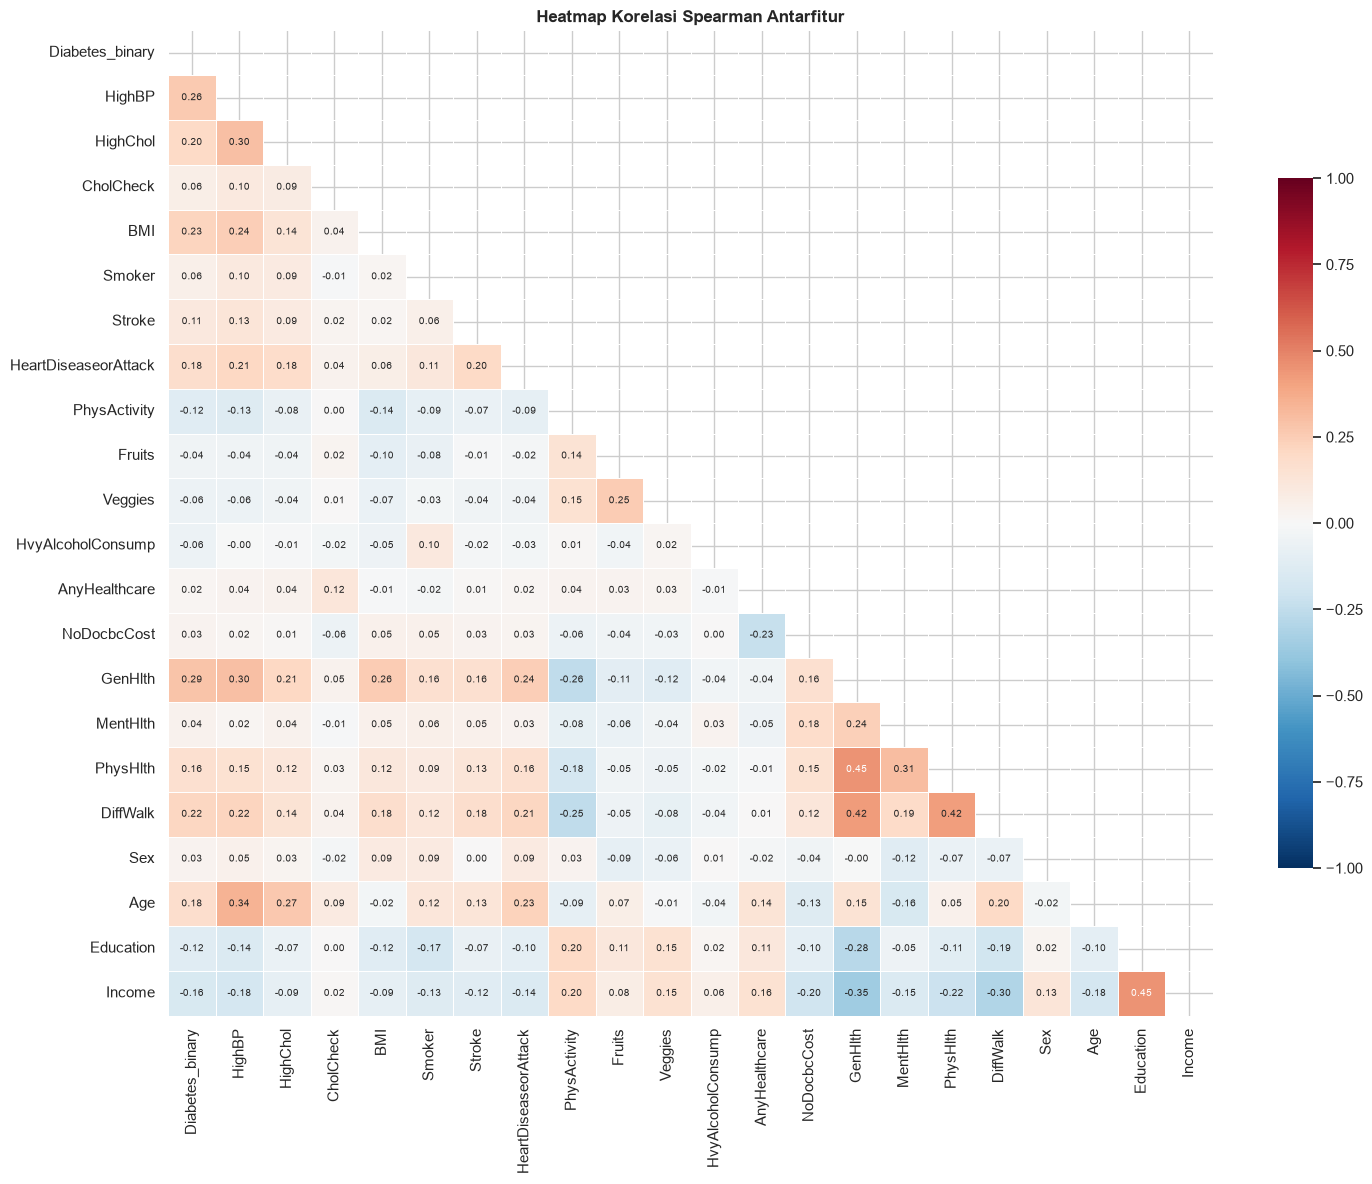

In [19]:
corr = df.corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(15, 12))
sns.heatmap(corr, mask=mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size": 7}, linewidths=0.4, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Heatmap Korelasi Spearman Antarfitur", fontweight="bold")
fig.tight_layout()
save_fig(fig, "eda_06_heatmap_korelasi")
plt.show()

In [20]:
# Pasangan fitur dengan korelasi absolut tertinggi (tanpa target)
pairs = (
    corr.drop(index=config.TARGET_COL, columns=config.TARGET_COL)
    .where(np.triu(np.ones((len(fitur), len(fitur)), dtype=bool), k=1))
    .stack()
    .rename("spearman")
    .reset_index()
    .rename(columns={"level_0": "fitur_1", "level_1": "fitur_2"})
)
pairs["abs"] = pairs["spearman"].abs()
pairs.sort_values("abs", ascending=False).head(8).drop(columns="abs").round(3)

,fitur_1,fitur_2,spearman
419,Education,Income,0.452
288,GenHlth,PhysHlth,0.452
289,GenHlth,DiffWalk,0.423
331,PhysHlth,DiffWalk,0.415
293,GenHlth,Income,-0.354
18,HighBP,Age,0.345
309,MentHlth,PhysHlth,0.308
356,DiffWalk,Income,-0.304


**Interpretasi:** Korelasi antarfitur tertinggi hanya 0,452, yaitu pada pasangan `Education`-`Income` dan `GenHlth`-`PhysHlth`, disusul `GenHlth`-`DiffWalk` (0,423) dan `PhysHlth`-`DiffWalk` (0,415). Pasangan-pasangan ini wajar karena saling berkaitan secara makna, misalnya orang yang sering sakit fisik cenderung menilai kesehatannya buruk.

Tidak ada pasangan yang korelasinya di atas 0,5, jadi tidak ada fitur yang benar-benar redundan. Semua 21 fitur dipertahankan untuk model.

## **12. Korelasi Fitur dengan Target**

Bagian ini mengurutkan fitur berdasarkan korelasi Spearman terhadap `Diabetes_binary`. Hasilnya tidak dipakai untuk membuang fitur, tetapi untuk memahami sinyal mana yang paling kuat dan nanti dibandingkan dengan hasil fitur unik explainability.

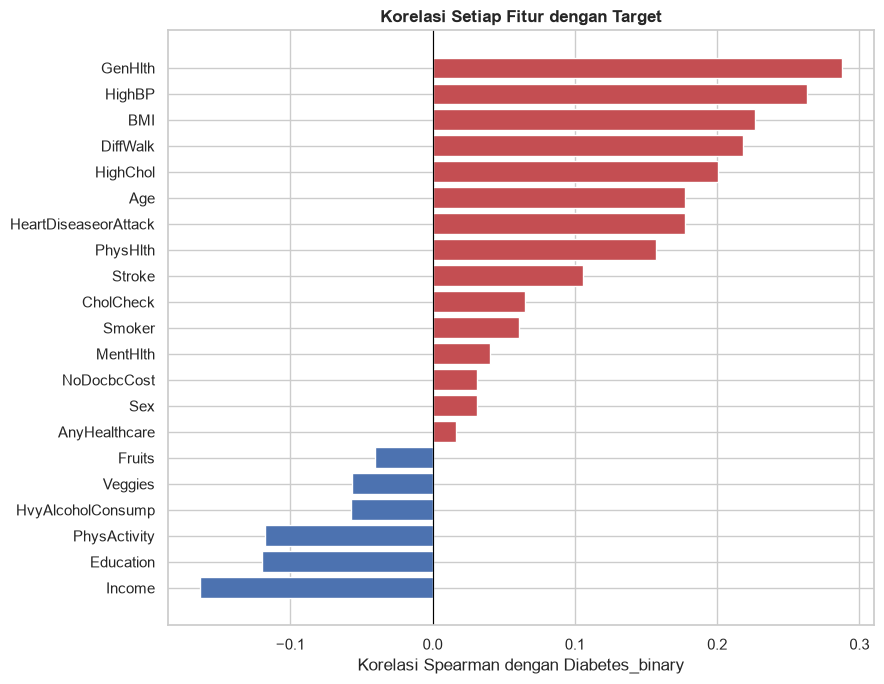

,spearman
GenHlth,0.288
HighBP,0.263
BMI,0.226
DiffWalk,0.218
HighChol,0.200
Age,0.178
HeartDiseaseorAttack,0.177
PhysHlth,0.157
Stroke,0.106
CholCheck,0.065


In [21]:
corr_target = corr[config.TARGET_COL].drop(config.TARGET_COL).sort_values()
fig, ax = plt.subplots(figsize=(9, 7))
colors = ["#C44E52" if v > 0 else "#4C72B0" for v in corr_target.values]
ax.barh(corr_target.index, corr_target.values, color=colors)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Korelasi Spearman dengan Diabetes_binary")
ax.set_title("Korelasi Setiap Fitur dengan Target", fontweight="bold")
fig.tight_layout()
save_fig(fig, "eda_07_korelasi_target")
plt.show()

corr_target.sort_values(ascending=False).round(3).to_frame("spearman")

**Interpretasi:** Lima fitur dengan korelasi positif tertinggi terhadap target adalah `GenHlth` (0,288), `HighBP` (0,263), `BMI` (0,226), `DiffWalk` (0,218), dan `HighChol` (0,200). Korelasi negatif paling kuat ada pada `Income` (-0,163), `Education` (-0,120), dan `PhysActivity` (-0,118).

Hal yang paling penting dari grafik ini justru nilai tertingginya yang tidak sampai 0,3. Artinya tidak ada satu fitur pun yang bisa memprediksi diabetes sendirian. Sinyalnya tersebar di banyak fitur yang masing-masing lemah, sehingga dibutuhkan model yang bisa mengombinasikan banyak fitur secara non-linear. Ini menjadi salah satu alasan pemilihan MLP.

Fitur dengan korelasi mendekati nol seperti `AnyHealthcare` (0,016) tidak dibuang, karena korelasi Spearman hanya mengukur hubungan monoton satu lawan satu. Fitur tersebut masih mungkin berguna lewat interaksinya dengan fitur lain, dan jumlah fitur yang hanya 21 juga tidak membebani model.

## **13. Butir EDA yang Tidak Berlaku**

Format laporan juga meminta *word count* (khusus data teks) dan contoh sampel citra per kelas (khusus data citra). Kedua butir tersebut tidak berlaku karena dataset ini berbentuk tabular. Sebagai gantinya, contoh sampel data tabular per kelas ditampilkan di bawah.

In [22]:
df.groupby(config.TARGET_COL, group_keys=False).sample(3, random_state=config.SEED)

,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
9362,0.0,0.0,0.0,1.0,27.0,1.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,0.0,1.0,1.0,5.0,0.0,0.0,4.0,6.0,7.0
1082,0.0,1.0,1.0,1.0,25.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,3.0,0.0,0.0,0.0,0.0,11.0,4.0,5.0
148278,0.0,1.0,0.0,1.0,21.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,3.0,3.0,2.0,0.0,0.0,2.0,6.0,8.0
113918,1.0,1.0,0.0,1.0,40.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0,3.0,0.0,0.0,0.0,0.0,8.0,5.0,7.0
217147,1.0,1.0,0.0,1.0,33.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,3.0,0.0,0.0,0.0,0.0,12.0,5.0,7.0
132644,1.0,1.0,0.0,1.0,31.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,4.0,2.0,15.0,1.0,0.0,12.0,4.0,5.0


## **14. Ringkasan Temuan dan Dampaknya pada Preprocessing**

| No | Temuan EDA | Dampak pada preprocessing / pemodelan |
|---|---|---|
| 1 | Semua kolom `float64` tetapi isinya bilangan bulat | Konversi ke integer saat load (sudah di `src/preprocessing.py`) |
| 2 | Tidak ada missing value | Tidak perlu imputasi |
| 3 | 24.206 baris duplikat (9,54%), mayoritas kelas negatif | Duplikat dihapus **sebelum** split untuk mencegah kebocoran data |
| 4 | 5.218 baris (2,06%) punya profil fitur sama tetapi label berbeda | Dipertahankan, dicatat sebagai noise label yang membatasi performa maksimal |
| 5a | Label 1 hanya berisi diabetes, 4.631 responden prediabetes ada di label 0 (berbeda dengan deskripsi Kaggle) | Kelas positif disebut "diabetes" di laporan dan aplikasi, file Diabetes_012 dipakai untuk analisis kesalahan |
| 5b | Kelas tidak seimbang (86,07% : 13,93%) | Split *stratified*, metrik utama recall/F1/PR-AUC, dasar fitur unik 1 |
| 6 | Skala fitur berbeda jauh (0-1, 12-98, 0-30) | StandardScaler pada fitur numerik dan ordinal, di-fit hanya pada data train |
| 7 | Fitur ordinal berhubungan monoton dengan label | Diperlakukan sebagai numerik, tidak di-one-hot |
| 8 | `MentHlth` dan `PhysHlth` didominasi nilai 0 | Transformasi tambahan dibandingkan di notebook 02 |
| 9 | Pola risiko BMI patah pada BMI 70 ke atas (599 baris) | Kandidat dihapus, keputusan final di notebook 02 |
| 10 | Tidak ada korelasi antarfitur di atas 0,5 | Semua 21 fitur dipertahankan |
| 11 | Korelasi fitur dengan target semuanya di bawah 0,3 | Mendukung pemakaian model non-linear (MLP) |

Seluruh grafik dari notebook ini tersimpan di `reports/figures/` dengan awalan `eda_` dan siap dipakai untuk laporan bagian 3.